# Deep Learning Case Study: Explainable AI for Diabetic Retinopathy Screening

## Project Overview

This project focuses on classifying retinal fundus images to identify the severity of diabetic retinopathy (DR) using deep learning techniques. The **APTOS 2019 Blindness Detection dataset**, obtained from Kaggle, contains retinal images categorized into five severity levels: **No DR, Mild, Moderate, Severe, and Proliferative DR**.

The project implements three image classification models: a custom CNN trained from scratch, a pretrained EfficientNetB0 model using transfer learning and fine-tuning, and a pretrained ResNet50 model. Their performance is evaluated using metrics such as accuracy, macro-F1 score, quadratic weighted kappa (QWK), and confusion matrices. The models are also evaluated for referable diabetic retinopathy detection using sensitivity, specificity, and ROC-AUC.

To improve interpretability, **Grad-CAM** is used to visualize image regions that influence model predictions. A confidence-based screening approach is also included to flag potentially uncertain predictions for further review.

## Project Phases

1. **Phase I – Dataset Understanding:** Download the APTOS 2019 dataset, examine its structure and labels, identify the five DR severity classes, and visualize sample retinal images.

2. **Phase II – Dataset Preparation:** Load the image annotations, preprocess and resize retinal images, prepare training, validation, and testing subsets, and examine class distribution.

3. **Phase III – CNN Implementation:** Build and train a custom CNN from scratch and evaluate its performance using training curves, accuracy, classification reports, and confusion matrices.

4. **Phase IV – Transfer Learning:** Implement EfficientNetB0 using pretrained weights, train the classification head, fine-tune the model, and evaluate its performance.

5. **Phase V – ResNet50 Implementation:** Implement and evaluate a pretrained ResNet50 model for five-class diabetic retinopathy severity classification.

6. **Phase VI – Model Comparison:** Compare the custom CNN, EfficientNetB0, and ResNet50 using accuracy, macro-F1, QWK, and other relevant evaluation metrics.

7. **Phase VII – Explainable AI Using Grad-CAM:** Generate heatmaps and overlay visualizations to examine which retinal regions influence the model's predictions, including correctly classified and misclassified examples.

8. **Phase VIII – Screening and Final Evaluation:** Evaluate referable DR detection, examine model predictions and uncertainty flags, summarize the results, and save the trained model weights and performance comparison files.

## Expected Outcome

The project combines deep learning-based diabetic retinopathy classification, model performance comparison, and visual explainability into a retinal image screening workflow. It demonstrates how deep learning models can classify retinal images into five DR severity levels and how Grad-CAM can help visualize regions influencing their predictions.

The confidence-based screening component aims to flag potentially uncertain predictions for further review. The project serves as an academic demonstration of AI-assisted retinal screening rather than a clinically validated diagnostic system.

## Technologies Used

- **Programming Language:** Python
- **Deep Learning Framework:** PyTorch
- **Dataset:** APTOS 2019 Blindness Detection
- **Models:** Custom CNN, EfficientNetB0, ResNet50
- **Explainable AI:** Grad-CAM
- **Evaluation:** Accuracy, macro-F1, QWK, sensitivity, specificity, ROC-AUC, and confusion matrices
- **Environment:** Google Colab

## Install and import libraries

In [1]:
!pip -q install kaggle scikit-learn seaborn

In [2]:
import os
import random
import shutil
import zipfile
import time
import copy
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageFile

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, f1_score, cohen_kappa_score,
    classification_report, confusion_matrix,
    roc_auc_score, precision_score, recall_score
)

ImageFile.LOAD_TRUNCATED_IMAGES = True

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: No GPU detected. In Colab, choose Runtime → Change runtime type → GPU.")

Device: cuda
GPU: Tesla T4


## Download the original APTOS dataset


In [3]:
!pip install -q kaggle

import os
import getpass

os.environ["KAGGLE_API_TOKEN"] = getpass.getpass(
    "Paste your Kaggle API token: "
)

DATA_ROOT = "/content/aptos_data"
os.makedirs(DATA_ROOT, exist_ok=True)

Paste your Kaggle API token: ··········


In [4]:
!kaggle --version

Kaggle CLI 2.0.2


In [5]:
!kaggle competitions list -s "aptos2019"

ref                                                                deadline             category      reward  teamCount  userHasEntered  
-----------------------------------------------------------------  -------------------  --------  ----------  ---------  --------------  
https://www.kaggle.com/competitions/aptos2019-blindness-detection  2019-09-07 23:59:00  Featured  50,000 Usd       2928            True  


In [6]:
!kaggle competitions download -c aptos2019-blindness-detection -p /content/aptos_data

100% 9.51G/9.51G [04:04<00:00, 41.8MB/s]



In [9]:

from pathlib import Path
import zipfile

# Define the dataset directory correctly
DATA_ROOT = Path("/content/aptos_data")
DATA_ROOT.mkdir(parents=True, exist_ok=True)

# Find downloaded ZIP files
zip_files = list(DATA_ROOT.glob("*.zip"))

if not zip_files:
    raise FileNotFoundError(
        "No ZIP file found in /content/aptos_data. "
        "Check that the Kaggle download completed successfully."
    )

# Extract ZIP files
for zip_path in zip_files:
    print("Extracting:", zip_path.name)
    with zipfile.ZipFile(zip_path, "r") as zf:
        zf.extractall(DATA_ROOT)

# Locate train.csv and train_images
csv_candidates = list(DATA_ROOT.rglob("train.csv"))
image_dirs = [
    p for p in DATA_ROOT.rglob("train_images")
    if p.is_dir()
]

if not csv_candidates:
    raise FileNotFoundError(
        "Could not find train.csv after extraction."
    )

if not image_dirs:
    raise FileNotFoundError(
        "Could not find train_images after extraction."
    )

CSV_PATH = csv_candidates[0]
IMAGE_DIR = image_dirs[0]

print("\nDataset extracted successfully!")
print("CSV:", CSV_PATH)
print("Images:", IMAGE_DIR)

Extracting: aptos2019-blindness-detection.zip

Dataset extracted successfully!
CSV: /content/aptos_data/train.csv
Images: /content/aptos_data/train_images


##Read labels, validate paths, and inspect the dataset

In [10]:
df = pd.read_csv(CSV_PATH)

required_columns = {"id_code", "diagnosis"}
if not required_columns.issubset(df.columns):
    raise ValueError(f"Expected columns {required_columns}; found {df.columns.tolist()}")

df["id_code"] = df["id_code"].astype(str)
df["label"] = pd.to_numeric(df["diagnosis"], errors="raise").astype(int)
df["image_path"] = df["id_code"].apply(lambda name: str(IMAGE_DIR / f"{name}.png"))

missing = (~df["image_path"].map(os.path.isfile)).sum()
print("Rows in CSV:", len(df))
print("Images missing:", int(missing))

df = df[df["image_path"].map(os.path.isfile)].reset_index(drop=True)
if df.empty:
    raise RuntimeError("No labelled images were found. Check CSV and image directory paths.")
if not set(df["label"].unique()).issubset({0, 1, 2, 3, 4}):
    raise ValueError("Unexpected labels found; expected grades 0 through 4.")

print("Usable labelled images:", len(df))
print(df["label"].value_counts().sort_index())

Rows in CSV: 3662
Images missing: 0
Usable labelled images: 3662
label
0    1805
1     370
2     999
3     193
4     295
Name: count, dtype: int64


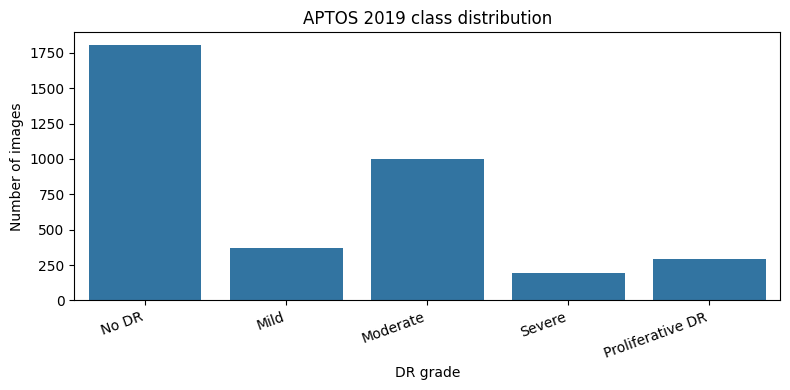

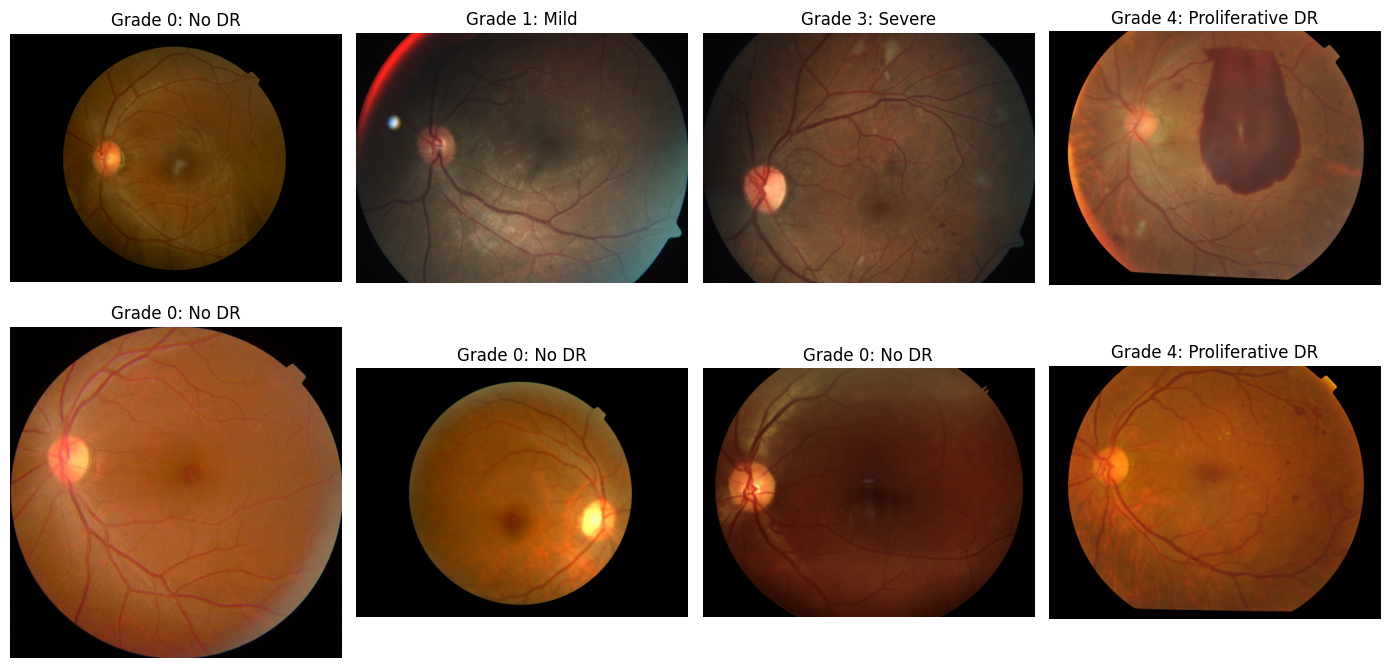

In [11]:
GRADE_NAMES = {
    0: "No DR",
    1: "Mild",
    2: "Moderate",
    3: "Severe",
    4: "Proliferative DR"
}

counts = df["label"].value_counts().sort_index()
plt.figure(figsize=(8, 4))
sns.barplot(x=[GRADE_NAMES[i] for i in counts.index], y=counts.values)
plt.title("APTOS 2019 class distribution")
plt.xlabel("DR grade")
plt.ylabel("Number of images")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
sample_rows = df.sample(min(8, len(df)), random_state=SEED).reset_index(drop=True)
for ax, (_, row) in zip(axes.flat, sample_rows.iterrows()):
    image = Image.open(row["image_path"]).convert("RGB")
    ax.imshow(image)
    ax.set_title(f"Grade {row['label']}: {GRADE_NAMES[row['label']]}")
    ax.axis("off")
for ax in axes.flat[len(sample_rows):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

## Split the labelled data


In [13]:
train_df, temp_df = train_test_split(
    df, test_size=0.30, stratify=df["label"], random_state=SEED
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, stratify=temp_df["label"], random_state=SEED
)

print(f"Train: {len(train_df)} ({len(train_df)/len(df):.1%})")
print(f"Validation: {len(val_df)} ({len(val_df)/len(df):.1%})")
print(f"Test: {len(test_df)} ({len(test_df)/len(df):.1%})")
print("\nTrain class counts:\n", train_df["label"].value_counts().sort_index())

Train: 2563 (70.0%)
Validation: 549 (15.0%)
Test: 550 (15.0%)

Train class counts:
 label
0    1263
1     259
2     699
3     135
4     207
Name: count, dtype: int64


##  PyTorch dataset and preprocessing

In [14]:
IMG_SIZE = 224
BATCH_SIZE = 16
NUM_WORKERS = 2

# ImageNet normalization is appropriate for ImageNet-pretrained EfficientNet/ResNet.
train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ColorJitter(brightness=0.10, contrast=0.10, saturation=0.05),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

class APTOSDataset(Dataset):
    def __init__(self, frame, transform=None):
        self.frame = frame.reset_index(drop=True).copy()
        self.transform = transform

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, idx):
        row = self.frame.iloc[idx]
        with Image.open(row["image_path"]) as im:
            image = im.convert("RGB")
        if self.transform:
            image = self.transform(image)
        label = int(row["label"])
        return image, label

train_ds = APTOSDataset(train_df, train_transform)
val_ds = APTOSDataset(val_df, eval_transform)
test_ds = APTOSDataset(test_df, eval_transform)

train_loader = DataLoader(
    train_ds, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == "cuda")
)
val_loader = DataLoader(
    val_ds, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == "cuda")
)
test_loader = DataLoader(
    test_ds, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == "cuda")
)

xb, yb = next(iter(train_loader))
print("Image batch:", xb.shape, "| label batch:", yb.shape)

Image batch: torch.Size([16, 3, 224, 224]) | label batch: torch.Size([16])


##Training utilities

In [15]:
class_counts = train_df["label"].value_counts().reindex(range(5), fill_value=0).values
if np.any(class_counts == 0):
    raise ValueError(f"At least one class is absent from the training split: {class_counts}")

class_weights = len(train_df) / (5.0 * class_counts)
class_weights = torch.tensor(class_weights, dtype=torch.float32, device=DEVICE)
print("Class counts:", class_counts)
print("Class weights:", class_weights.cpu().numpy())

Class counts: [1263  259  699  135  207]
Class weights: [0.40585905 1.9791505  0.73333335 3.7970371  2.4763286 ]


In [16]:
def run_epoch(model, loader, criterion, optimizer=None):
    training = optimizer is not None
    model.train(training)
    total_loss = 0.0
    all_labels, all_probs = [], []

    for images, labels in loader:
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            logits = model(images)
            loss = criterion(logits, labels)
            if training:
                loss.backward()
                optimizer.step()

        total_loss += loss.item() * images.size(0)
        probs = torch.softmax(logits.detach(), dim=1)
        all_probs.append(probs.cpu().numpy())
        all_labels.append(labels.detach().cpu().numpy())

    y_true = np.concatenate(all_labels)
    y_probs = np.concatenate(all_probs)
    y_pred = y_probs.argmax(axis=1)
    return total_loss / len(loader.dataset), y_true, y_probs, y_pred


def fit_model(model, train_loader, val_loader, epochs=3, lr=1e-3, name="model"):
    model = model.to(DEVICE)
    criterion = nn.CrossEntropyLoss(weight=class_weights)
    optimizer = torch.optim.AdamW(
        (p for p in model.parameters() if p.requires_grad),
        lr=lr, weight_decay=1e-4
    )
    best_kappa = -float("inf")
    best_state = copy.deepcopy(model.state_dict())
    history = []

    for epoch in range(1, epochs + 1):
        start = time.time()
        train_loss, _, _, _ = run_epoch(model, train_loader, criterion, optimizer)
        val_loss, y_true, y_probs, y_pred = run_epoch(model, val_loader, criterion)
        val_f1 = f1_score(y_true, y_pred, average="macro", zero_division=0)
        val_kappa = cohen_kappa_score(y_true, y_pred, weights="quadratic")
        history.append({
            "epoch": epoch, "train_loss": train_loss, "val_loss": val_loss,
            "val_macro_f1": val_f1, "val_qwk": val_kappa
        })
        print(
            f"{name} | Epoch {epoch}/{epochs} | "
            f"train loss {train_loss:.4f} | val loss {val_loss:.4f} | "
            f"macro-F1 {val_f1:.4f} | QWK {val_kappa:.4f} | "
            f"{time.time()-start:.1f}s"
        )
        if np.isfinite(val_kappa) and val_kappa > best_kappa:
            best_kappa = val_kappa
            best_state = copy.deepcopy(model.state_dict())

    model.load_state_dict(best_state)
    return model, pd.DataFrame(history)

## Model 1: custom CNN baseline

In [19]:
class SmallCNN(nn.Module):
    def __init__(self, num_classes=5):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
            nn.Conv2d(128, 256, 3, padding=1), nn.BatchNorm2d(256), nn.ReLU(inplace=True),
            nn.AdaptiveAvgPool2d((1, 1))
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.35),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        return self.classifier(self.features(x))

EPOCHS_CNN = 4  # Increase after the first successful run
cnn_model, cnn_history = fit_model(
    SmallCNN(), train_loader, val_loader,
    epochs=EPOCHS_CNN, lr=1e-3, name="Custom CNN"
)

Custom CNN | Epoch 1/4 | train loss 1.5326 | val loss 1.7765 | macro-F1 0.0851 | QWK -0.2233 | 322.2s
Custom CNN | Epoch 2/4 | train loss 1.4088 | val loss 1.7959 | macro-F1 0.1114 | QWK -0.2348 | 308.0s
Custom CNN | Epoch 3/4 | train loss 1.3525 | val loss 1.3102 | macro-F1 0.3498 | QWK 0.4515 | 308.4s
Custom CNN | Epoch 4/4 | train loss 1.3044 | val loss 1.2774 | macro-F1 0.4228 | QWK 0.6189 | 302.4s


##  Model 2: EfficientNetB0 (transfer learning)

In [21]:
# Pretrained ImageNet weights require internet access in the Colab runtime.
try:
    efficient_weights = models.EfficientNet_B0_Weights.DEFAULT
    efficient_model = models.efficientnet_b0(weights=efficient_weights)
except Exception as exc:
    print("Could not download pretrained weights; using randomly initialized EfficientNetB0.")
    print("Reason:", repr(exc))
    efficient_model = models.efficientnet_b0(weights=None)

for p in efficient_model.parameters():
    p.requires_grad = False

in_features = efficient_model.classifier[1].in_features
efficient_model.classifier[1] = nn.Linear(in_features, 5)
for p in efficient_model.classifier.parameters():
    p.requires_grad = True

EPOCHS_EFFICIENT = 3
efficient_model, efficient_history = fit_model(
    efficient_model, train_loader, val_loader,
    epochs=EPOCHS_EFFICIENT, lr=1e-3, name="EfficientNetB0 frozen"
)

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 184MB/s]


EfficientNetB0 frozen | Epoch 1/3 | train loss 1.2936 | val loss 1.1145 | macro-F1 0.5418 | QWK 0.7359 | 297.0s
EfficientNetB0 frozen | Epoch 2/3 | train loss 1.1019 | val loss 1.0631 | macro-F1 0.5175 | QWK 0.7394 | 295.5s
EfficientNetB0 frozen | Epoch 3/3 | train loss 1.0251 | val loss 1.0349 | macro-F1 0.5701 | QWK 0.7812 | 300.8s


###  EfficientNet fine-tuning


In [26]:
# Fine-tune final EfficientNet feature block and classifier.
for p in efficient_model.parameters():
    p.requires_grad = False
for p in efficient_model.features[-1].parameters():
    p.requires_grad = True
for p in efficient_model.classifier.parameters():
    p.requires_grad = True

EPOCHS_FINETUNE = 2
efficient_model, efficient_ft_history = fit_model(
    efficient_model, train_loader, val_loader,
    epochs=EPOCHS_FINETUNE, lr=1e-4, name="EfficientNetB0 fine-tuned"
)

EfficientNetB0 fine-tuned | Epoch 1/2 | train loss 0.9644 | val loss 0.9839 | macro-F1 0.5897 | QWK 0.8082 | 299.1s
EfficientNetB0 fine-tuned | Epoch 2/2 | train loss 0.9444 | val loss 0.9821 | macro-F1 0.5932 | QWK 0.8043 | 305.2s


##Model 3: ResNet50 (transfer learning)

In [22]:
try:
    resnet_weights = models.ResNet50_Weights.DEFAULT
    resnet_model = models.resnet50(weights=resnet_weights)
except Exception as exc:
    print("Could not download pretrained weights; using randomly initialized ResNet50.")
    print("Reason:", repr(exc))
    resnet_model = models.resnet50(weights=None)

for p in resnet_model.parameters():
    p.requires_grad = False

in_features = resnet_model.fc.in_features
resnet_model.fc = nn.Linear(in_features, 5)
for p in resnet_model.fc.parameters():
    p.requires_grad = True

EPOCHS_RESNET = 3
resnet_model, resnet_history = fit_model(
    resnet_model, train_loader, val_loader,
    epochs=EPOCHS_RESNET, lr=1e-3, name="ResNet50 frozen"
)

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 183MB/s]


ResNet50 frozen | Epoch 1/3 | train loss 1.3108 | val loss 1.1530 | macro-F1 0.5349 | QWK 0.7533 | 298.9s
ResNet50 frozen | Epoch 2/3 | train loss 1.0938 | val loss 1.1175 | macro-F1 0.5011 | QWK 0.7766 | 303.1s
ResNet50 frozen | Epoch 3/3 | train loss 1.0083 | val loss 1.0477 | macro-F1 0.5359 | QWK 0.7378 | 298.4s


## Evaluate all models on the held-out test set

In [27]:
def evaluate_classifier(model, loader, model_name):
    criterion = nn.CrossEntropyLoss(weight=class_weights)
    test_loss, y_true, y_probs, y_pred = run_epoch(model, loader, criterion)
    qwk = cohen_kappa_score(y_true, y_pred, weights="quadratic")
    macro_f1 = f1_score(y_true, y_pred, average="macro", zero_division=0)
    accuracy = accuracy_score(y_true, y_pred)

    # Referable DR is defined here as grade >= 2 (moderate or worse).
    y_ref_true = (y_true >= 2).astype(int)
    y_ref_score = y_probs[:, 2:].sum(axis=1)
    y_ref_pred = (y_ref_score >= 0.5).astype(int)
    sensitivity = recall_score(y_ref_true, y_ref_pred, zero_division=0)
    specificity = recall_score(1 - y_ref_true, 1 - y_ref_pred, zero_division=0)
    try:
        auc = roc_auc_score(y_ref_true, y_ref_score)
    except ValueError:
        auc = np.nan

    metrics = {
        "model": model_name,
        "test_loss": test_loss,
        "accuracy": accuracy,
        "macro_f1": macro_f1,
        "quadratic_weighted_kappa": qwk,
        "referable_sensitivity_at_0.5": sensitivity,
        "referable_specificity_at_0.5": specificity,
        "referable_auc": auc
    }
    return metrics, y_true, y_probs, y_pred

results = []
predictions = {}

for name, model in [
    ("Custom CNN", cnn_model),
    ("EfficientNetB0 fine-tuned", efficient_model),
    ("ResNet50", resnet_model)
]:
    metrics, y_true, y_probs, y_pred = evaluate_classifier(model, test_loader, name)
    results.append(metrics)
    predictions[name] = (y_true, y_probs, y_pred)
    print("\n", name)
    print(classification_report(
        y_true, y_pred, labels=[0,1,2,3,4],
        target_names=[GRADE_NAMES[i] for i in range(5)],
        zero_division=0
    ))

results_df = pd.DataFrame(results).sort_values(
    "quadratic_weighted_kappa", ascending=False
).reset_index(drop=True)
display(results_df)


 Custom CNN
                  precision    recall  f1-score   support

           No DR       0.92      0.94      0.93       271
            Mild       0.27      0.36      0.31        56
        Moderate       0.58      0.51      0.54       150
          Severe       0.50      0.17      0.26        29
Proliferative DR       0.21      0.27      0.24        44

        accuracy                           0.67       550
       macro avg       0.49      0.45      0.45       550
    weighted avg       0.68      0.67      0.67       550


 EfficientNetB0 fine-tuned
                  precision    recall  f1-score   support

           No DR       0.93      0.95      0.94       271
            Mild       0.47      0.50      0.49        56
        Moderate       0.72      0.49      0.58       150
          Severe       0.31      0.48      0.38        29
Proliferative DR       0.41      0.64      0.50        44

        accuracy                           0.73       550
       macro avg       0.5

,model,test_loss,accuracy,macro_f1,quadratic_weighted_kappa,referable_sensitivity_at_0.5,referable_specificity_at_0.5,referable_auc
0,EfficientNetB0 fine-tuned,0.968957,0.729091,0.577605,0.821988,0.896861,0.886850,0.962247
1,ResNet50,1.107321,0.681818,0.491406,0.814509,0.946188,0.856269,0.960738
2,Custom CNN,1.237595,0.667273,0.453335,0.661323,0.964126,0.740061,0.914140


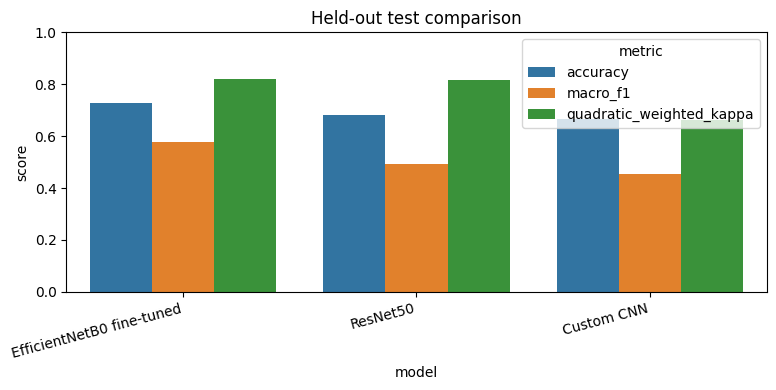

In [28]:
plt.figure(figsize=(8, 4))
plot_df = results_df.melt(
    id_vars="model", value_vars=["accuracy", "macro_f1", "quadratic_weighted_kappa"],
    var_name="metric", value_name="score"
)
sns.barplot(data=plot_df, x="model", y="score", hue="metric")
plt.ylim(0, 1)
plt.xticks(rotation=15, ha="right")
plt.title("Held-out test comparison")
plt.tight_layout()
plt.show()

##  Confusion matrix for the best model

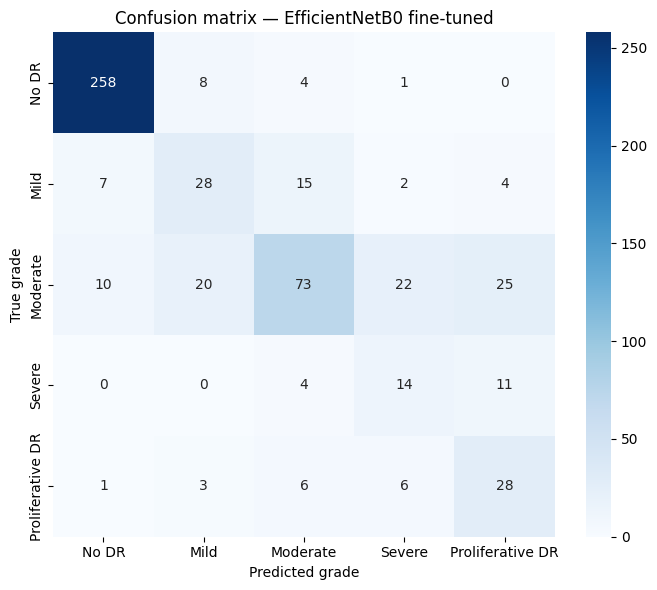

In [29]:
best_name = results_df.iloc[0]["model"]
model_map = {
    "Custom CNN": cnn_model,
    "EfficientNetB0 fine-tuned": efficient_model,
    "ResNet50": resnet_model
}
best_model = model_map[best_name]
y_true, y_probs, y_pred = predictions[best_name]

cm = confusion_matrix(y_true, y_pred, labels=[0,1,2,3,4])
plt.figure(figsize=(7, 6))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=[GRADE_NAMES[i] for i in range(5)],
    yticklabels=[GRADE_NAMES[i] for i in range(5)]
)
plt.xlabel("Predicted grade")
plt.ylabel("True grade")
plt.title(f"Confusion matrix — {best_name}")
plt.tight_layout()
plt.show()

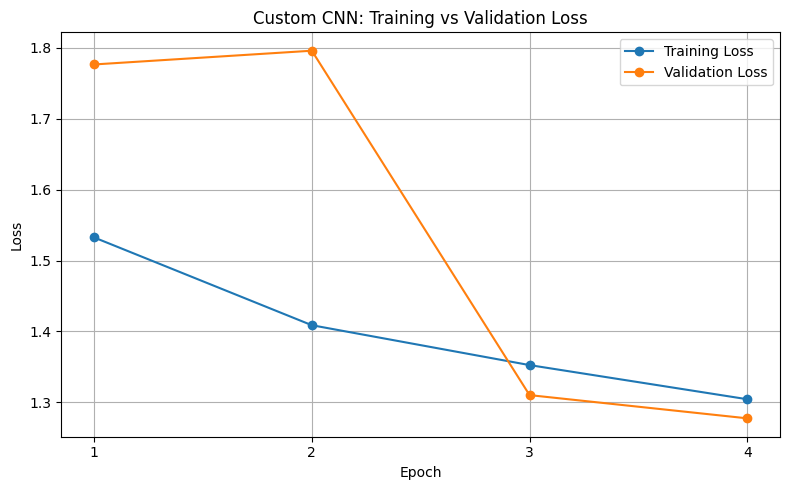

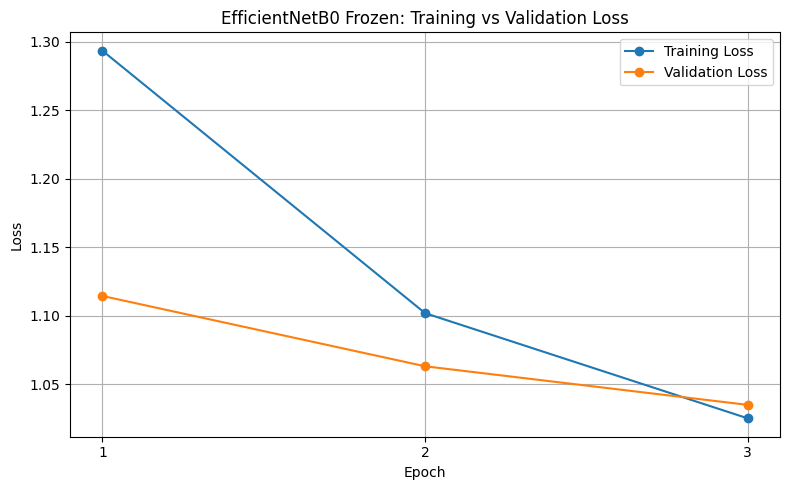

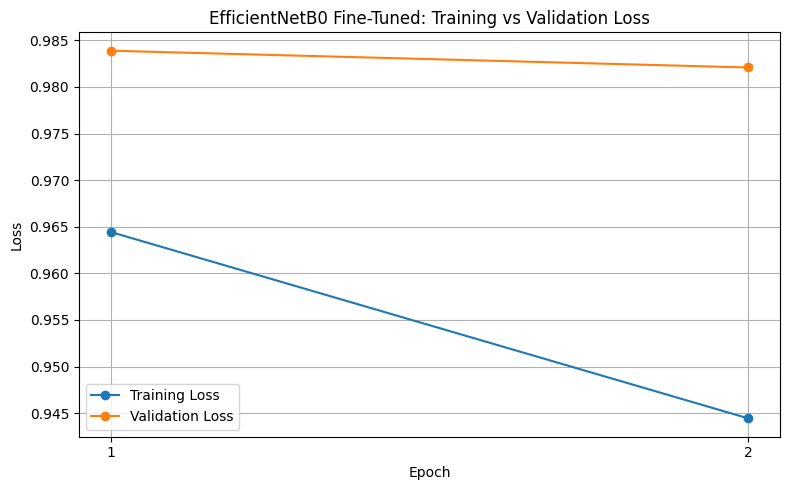

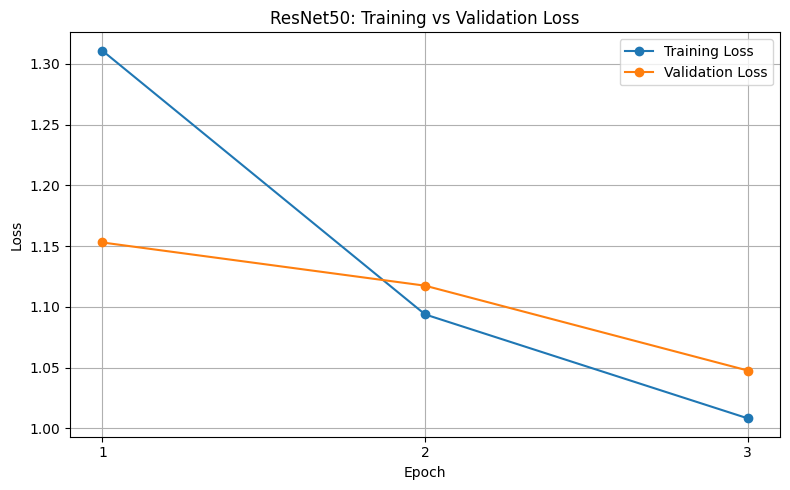

In [32]:
import matplotlib.pyplot as plt

def plot_loss_curves(history, model_name):
    plt.figure(figsize=(8, 5))

    plt.plot(history["epoch"], history["train_loss"],
             marker="o", label="Training Loss")

    plt.plot(history["epoch"], history["val_loss"],
             marker="o", label="Validation Loss")

    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title(f"{model_name}: Training vs Validation Loss")
    plt.xticks(history["epoch"])
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()


# 1. Custom CNN
plot_loss_curves(cnn_history, "Custom CNN")

# 2. EfficientNetB0 (frozen)
plot_loss_curves(efficient_history, "EfficientNetB0 Frozen")

# 3. EfficientNetB0 (fine-tuned)
plot_loss_curves(efficient_ft_history, "EfficientNetB0 Fine-Tuned")

# 4. ResNet50
plot_loss_curves(resnet_history, "ResNet50")


##Grad-CAM for EfficientNetB0



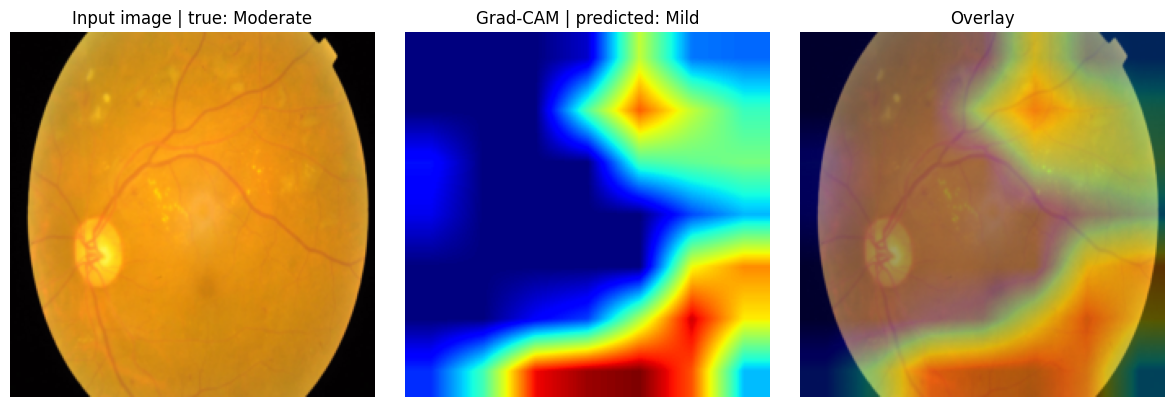

In [38]:
def gradcam_efficientnet(model, image_tensor, class_idx=None):
    model.eval()
    activations = []
    gradients = []
    # Hook the final convolution itself to avoid in-place activation hook issues.
    target_layer = model.features[-1][0]

    def forward_hook(module, inputs, output):
        activations.append(output)

    def backward_hook(module, grad_input, grad_output):
        gradients.append(grad_output[0])

    h1 = target_layer.register_forward_hook(forward_hook)
    h2 = target_layer.register_full_backward_hook(backward_hook)

    x = image_tensor.unsqueeze(0).to(DEVICE)
    model.zero_grad(set_to_none=True)
    logits = model(x)
    if class_idx is None:
        class_idx = int(logits.argmax(dim=1).item())
    score = logits[0, class_idx]
    score.backward()

    acts = activations[0].detach()
    grads = gradients[0].detach()
    weights = grads.mean(dim=(2, 3), keepdim=True)
    cam = (weights * acts).sum(dim=1, keepdim=True)
    cam = torch.relu(cam)
    cam = torch.nn.functional.interpolate(
        cam, size=(IMG_SIZE, IMG_SIZE), mode="bilinear", align_corners=False
    )[0, 0]
    cam = cam.cpu().numpy()
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)

    h1.remove()
    h2.remove()
    return cam, class_idx

# Pick one test image.
sample_idx = 0
sample_image, sample_label = test_ds[sample_idx]
cam, predicted_class = gradcam_efficientnet(efficient_model, sample_image)

# Convert normalized tensor back to a displayable RGB image.
mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])
display_img = sample_image.permute(1, 2, 0).cpu().numpy() * std + mean
display_img = np.clip(display_img, 0, 1)

plt.figure(figsize=(12, 4))
plt.subplot(1, 3, 1)
plt.imshow(display_img)
plt.title(f"Input image | true: {GRADE_NAMES[int(sample_label)]}")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(cam, cmap="jet")
plt.title(f"Grad-CAM | predicted: {GRADE_NAMES[predicted_class]}")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(display_img)
plt.imshow(cam, cmap="jet", alpha=0.35)
plt.title("Overlay")
plt.axis("off")
plt.tight_layout()
plt.show()

Test dataset index: 4
Actual grade: No DR
Predicted grade: No DR


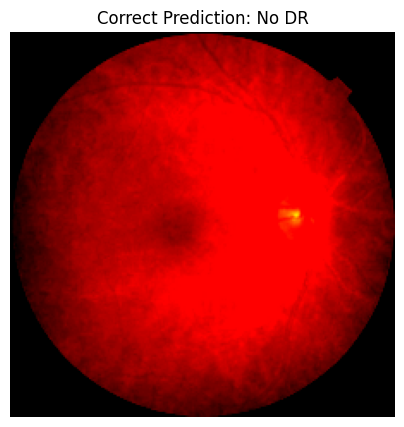

In [37]:
import torch
import matplotlib.pyplot as plt

# Use the fine-tuned EfficientNetB0 model from your notebook
efficient_model.eval()

correct_index = None

for idx in range(len(test_ds)):
    image, label = test_ds[idx]

    # Look only for images whose actual class is No DR (class 0)
    if label != 0:
        continue

    with torch.no_grad():
        output = efficient_model(image.unsqueeze(0).to(DEVICE))
        predicted_label = output.argmax(dim=1).item()

    if predicted_label == 0:
        correct_index = idx
        break

if correct_index is None:
    print("No correctly classified No DR image found.")
else:
    image, label = test_ds[correct_index]

    print("Test dataset index:", correct_index)
    print("Actual grade: No DR")
    print("Predicted grade: No DR")

    plt.figure(figsize=(5, 5))
    plt.imshow(image.permute(1, 2, 0).cpu().numpy())
    plt.title("Correct Prediction: No DR")
    plt.axis("off")
    plt.show()

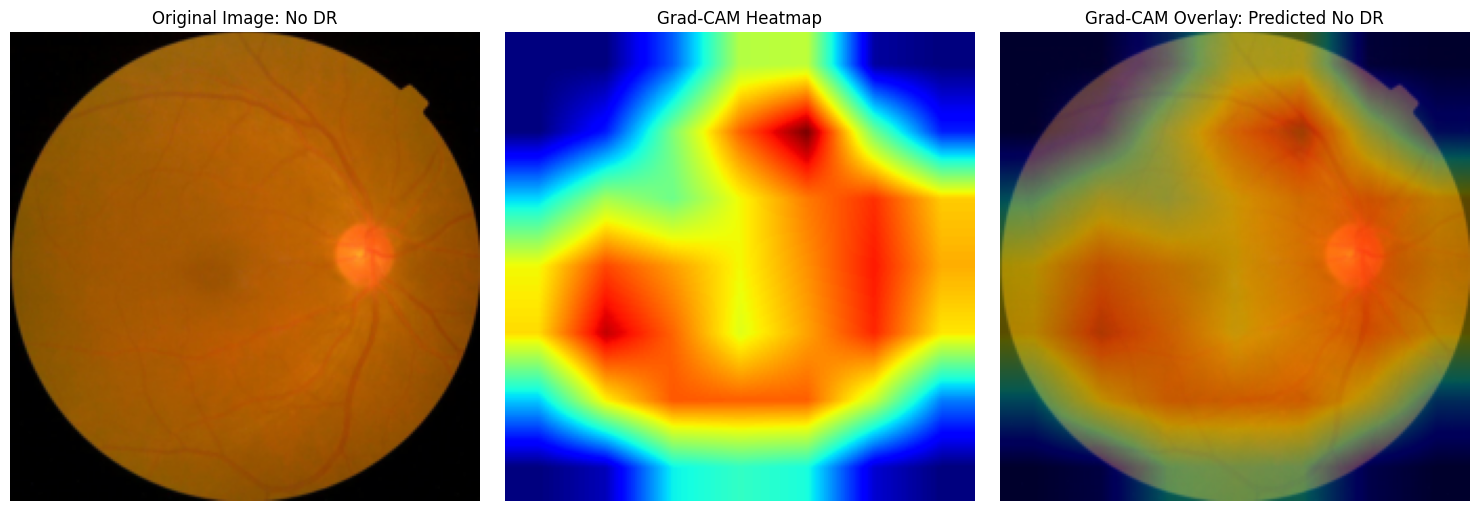

In [39]:
import numpy as np
import matplotlib.pyplot as plt

# Get the correctly classified No DR image
sample_image, sample_label = test_ds[correct_index]

# Generate Grad-CAM using your fine-tuned EfficientNetB0
cam, predicted_class = gradcam_efficientnet(
    efficient_model, sample_image
)

# Convert the normalized image tensor back to RGB
mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

display_img = (
    sample_image.permute(1, 2, 0).cpu().numpy() * std + mean
)
display_img = np.clip(display_img, 0, 1)

# Display the original image, heatmap, and overlay
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(display_img)
plt.title("Original Image: No DR")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(cam, cmap="jet")
plt.title("Grad-CAM Heatmap")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(display_img)
plt.imshow(cam, cmap="jet", alpha=0.35)
plt.title(f"Grad-CAM Overlay: Predicted {GRADE_NAMES[predicted_class]}")
plt.axis("off")

plt.tight_layout()
plt.show()

## Confidence-based human-review flag



In [40]:
def predict_with_review_flag(model, image_tensor, confidence_threshold=0.60):
    model.eval()
    with torch.no_grad():
        logits = model(image_tensor.unsqueeze(0).to(DEVICE))
        probs = torch.softmax(logits, dim=1)[0].cpu().numpy()
    predicted_grade = int(np.argmax(probs))
    confidence = float(np.max(probs))
    return {
        "predicted_grade": predicted_grade,
        "predicted_label": GRADE_NAMES[predicted_grade],
        "confidence": confidence,
        "flag_for_human_review": confidence < confidence_threshold,
        "class_probabilities": {GRADE_NAMES[i]: float(probs[i]) for i in range(5)}
    }

example = predict_with_review_flag(best_model, sample_image, confidence_threshold=0.60)
example

{'predicted_grade': 0,
 'predicted_label': 'No DR',
 'confidence': 0.6233972311019897,
 'flag_for_human_review': False,
 'class_probabilities': {'No DR': 0.6233972311019897,
  'Mild': 0.20199763774871826,
  'Moderate': 0.0729447528719902,
  'Severe': 0.02335524745285511,
  'Proliferative DR': 0.07830505818128586}}

### Save model weights and results



In [41]:
OUTPUT_DIR = Path("/content/dr_case_study_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

torch.save(cnn_model.state_dict(), OUTPUT_DIR / "custom_cnn_aptos.pth")
torch.save(efficient_model.state_dict(), OUTPUT_DIR / "efficientnet_b0_aptos.pth")
torch.save(resnet_model.state_dict(), OUTPUT_DIR / "resnet50_aptos.pth")
results_df.to_csv(OUTPUT_DIR / "test_model_comparison.csv", index=False)

print("Saved files:")
for p in OUTPUT_DIR.iterdir():
    print(p.name, f"({p.stat().st_size / (1024**2):.1f} MB)")

Saved files:
test_model_comparison.csv (0.0 MB)
efficientnet_b0_aptos.pth (15.6 MB)
custom_cnn_aptos.pth (1.5 MB)
resnet50_aptos.pth (90.0 MB)
